# Olist: доставка и клиентский опыт

Цель — определить региональные приоритеты улучшения доставки и исследовать связь просрочек с оценками. Когорта: январь 2017 — август 2018. Единица наблюдения: заказ. Источник: [Olist / Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). Методология и участие ИИ описаны в документации проекта.

In [1]:
from pathlib import Path
import sys
import sqlite3
import pandas as pd
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / "src/analysis.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/analysis.py").exists(), "Open this notebook inside the project"
sys.path.insert(0, str(ROOT))
from src.analysis import load_data, prepare, summarize, plot_results, export_results

## Качество данных и сборка витрины

Позиции и оплаты агрегируются до заказа перед соединением. Для нескольких отзывов выбирается последний ответ; альтернативы проверяются ниже. Денежные суммы сверяются в целых центаво.

In [2]:
raw = load_data(ROOT)
mart, quality, prepared = prepare(raw)
summary, tables = summarize(mart, quality)
display(quality.loc[(quality["count"] > 0) & (quality["interpretation"] != "inventory")])
print(f"Rows: {len(mart):,}; unique orders: {mart.order_id.nunique():,}")

Rows: 99,441; unique orders: 99,441


,table,check,count,interpretation
13,orders,missing:order_approved_at,160,diagnostic
14,orders,missing:order_delivered_carrier_date,1783,diagnostic
15,orders,missing:order_delivered_customer_date,2965,diagnostic
38,reviews,missing:review_comment_title,87656,diagnostic
39,reviews,missing:review_comment_message,58247,diagnostic
45,products,missing:product_category_name,610,diagnostic
46,products,missing:product_name_lenght,610,diagnostic
47,products,missing:product_description_lenght,610,diagnostic
48,products,missing:product_photos_qty,610,diagnostic
49,products,missing:product_weight_g,2,diagnostic


## Объём и финансовые показатели

Оборот товаров исключает доставку и не является выручкой платформы. Статусы и знаменатели сохранены отдельно.

In [3]:
display(pd.Series(summary, name="value").to_frame())
display(tables["order_status"])

,value
scope_start,2017-01-01
scope_end_inclusive,2018-08-31
source_orders,99441
purchase_min,2016-09-04 21:15:19
purchase_max,2018-10-17 17:30:18
scope_orders,99092
delivered_orders,96211
delivery_eligible_orders,96203
delivery_excluded_orders,8
late_orders,6531


,status,orders
0,delivered,96211
1,shipped,1097
2,unavailable,602
3,canceled,580
4,processing,299
5,invoiced,296
6,created,5
7,approved,2


## Динамика и региональные приоритеты

Просрочка определяется относительно обещанной календарной даты. В региональном рейтинге минимум 500 пригодных заказов; полный набор штатов сохранён в CSV.

,purchase_month,orders,delivered_orders,eligible_orders,late_orders,merchandise_cents,merchandise_brl,late_rate,orders_mom_pct
0,2017-01,800,750,750,22,11179836,111798.36,0.0293,NaN
1,2017-02,1780,1653,1653,49,23422340,234223.4,0.0296,122.5000
2,2017-03,2682,2546,2546,116,35919885,359198.85,0.0456,50.6742
3,2017-04,2404,2303,2303,151,34066968,340669.68,0.0656,-10.3654
4,2017-05,3700,3546,3545,106,48933825,489338.25,0.0299,53.9101
5,2017-06,3245,3135,3135,95,42192337,421923.37,0.0303,-12.2973
6,2017-07,4026,3872,3872,108,48160452,481604.52,0.0279,24.0678
7,2017-08,4331,4193,4193,122,55469970,554699.7,0.0291,7.5758
8,2017-09,4285,4150,4150,182,60739967,607399.67,0.0439,-1.0621
9,2017-10,4631,4478,4478,187,64824765,648247.65,0.0418,8.0747


,customer_state,orders,late_orders,median_delivery_days,late_rate,low_ci,high_ci,ranking_eligible
25,SP,40399,1817,7.2040,0.045,0.0430,0.0470,True
18,RJ,12310,1495,12.0361,0.1214,0.1158,0.1273,True
10,MG,11319,519,10.3059,0.0459,0.0422,0.0499,True
4,BA,3253,396,16.9132,0.1217,0.1109,0.1334,True
22,RS,5327,325,13.1733,0.061,0.0549,0.0678,True
23,SC,3537,291,13.0072,0.0823,0.0737,0.0918,True
7,ES,1992,214,13.6329,0.1074,0.0946,0.1218,True
17,PR,4903,199,10.4224,0.0406,0.0354,0.0465,True
5,CE,1273,176,18.1708,0.1383,0.1204,0.1583,True
15,PE,1587,153,15.7028,0.0964,0.0828,0.1119,True


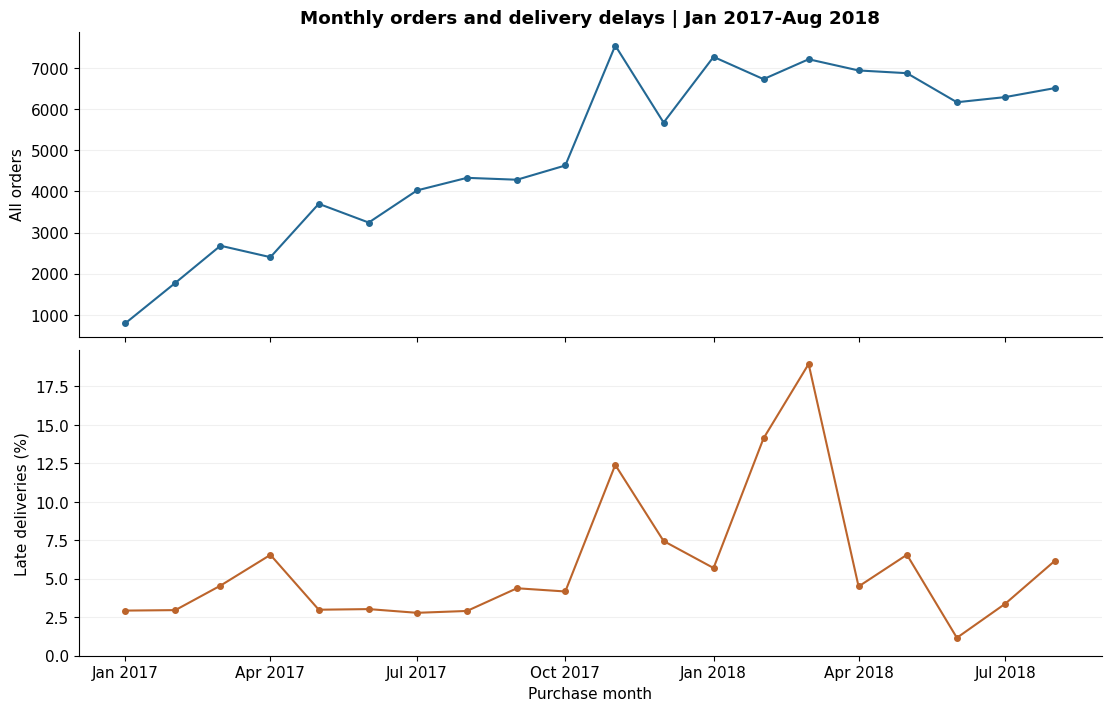

In [4]:
display(tables["monthly_metrics"].round(4))
display(tables["state_delivery"].head(10).round(4))
figures = plot_results(mart, tables)
import matplotlib.pyplot as plt
plt.close("all")
display(figures["01_monthly_orders_and_delays"])

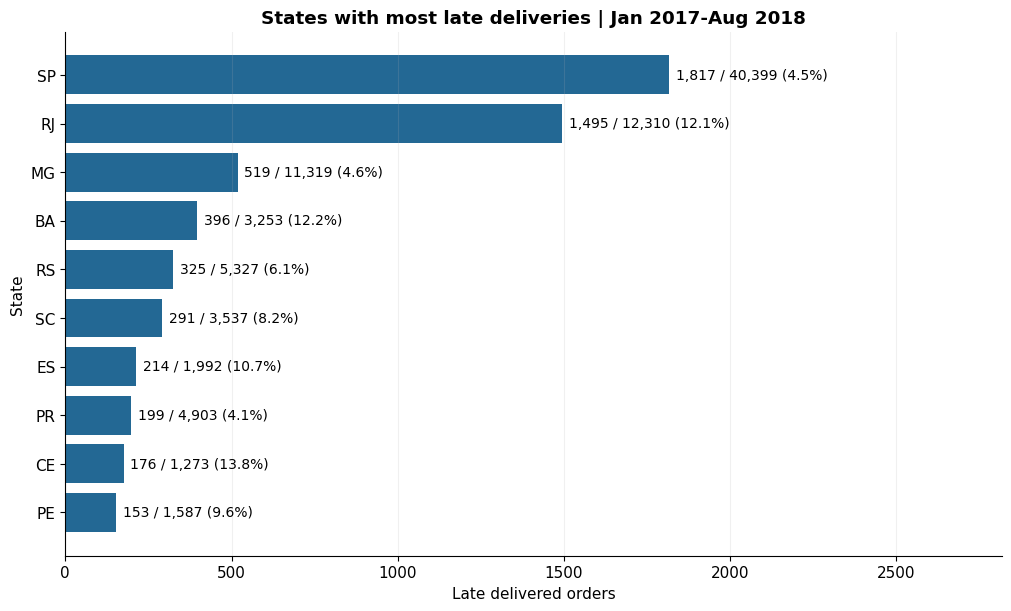

In [5]:
display(figures["02_state_priorities"])

SP и RJ дают примерно половину задержек. SP приоритетен по абсолютному количеству; RJ сочетает большой объём и повышенную долю просрочек. Для диагностики причин нужны данные о перевозчиках и процессах.

## Отзывы и устойчивость результата

Низкая оценка: 1–2. В знаменателе только заказы с оценкой. Интервалы Уилсона описательные и не учитывают кластеризацию.

,late,reviewed_orders,mean_review,low_reviews,low_review_rate,low_ci,high_ci,eligible_orders,review_coverage
0,False,89182,4.2912,8247,0.0925,0.0906,0.0944,89672,0.9945
1,True,6378,2.2706,3981,0.6242,0.6122,0.6360,6531,0.9766


,definition,on_time_n,late_n,on_time_low_rate,late_low_rate,difference_pp
0,Latest review,89182,6378,0.0925,0.6242,53.1703
1,First review,89182,6378,0.0924,0.6235,53.1143
2,Only answers after delivery,89005,1907,0.0923,0.1945,10.2226
3,Exclude Aug 2018,83237,5993,0.0938,0.6369,54.3117


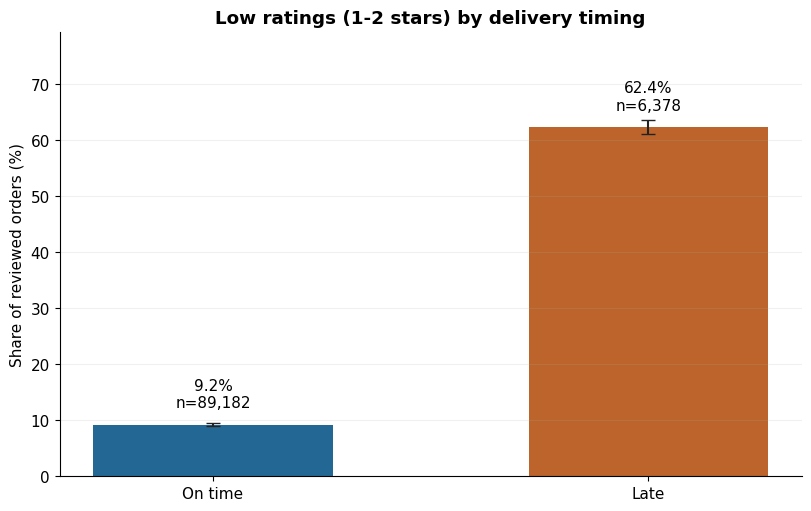

In [6]:
display(tables["review_comparison"].round(4))
display(tables["sensitivity"].round(4))
display(figures["03_reviews_and_delays"])

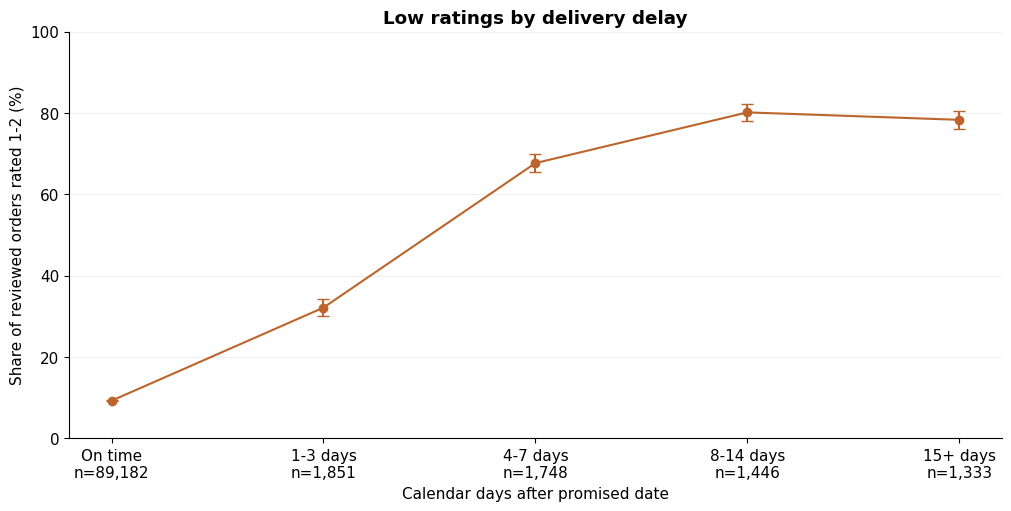

In [7]:
display(figures["04_delay_severity"])

Разница низких оценок составляет 53,17 п.п., но среди ответов после получения — 10,22 п.п. Отбор по моменту ответа меняет состав групп. Это не доказательство причинного эффекта задержки. Стандартизация по штату и месяцу также не устраняет все различия между группами.

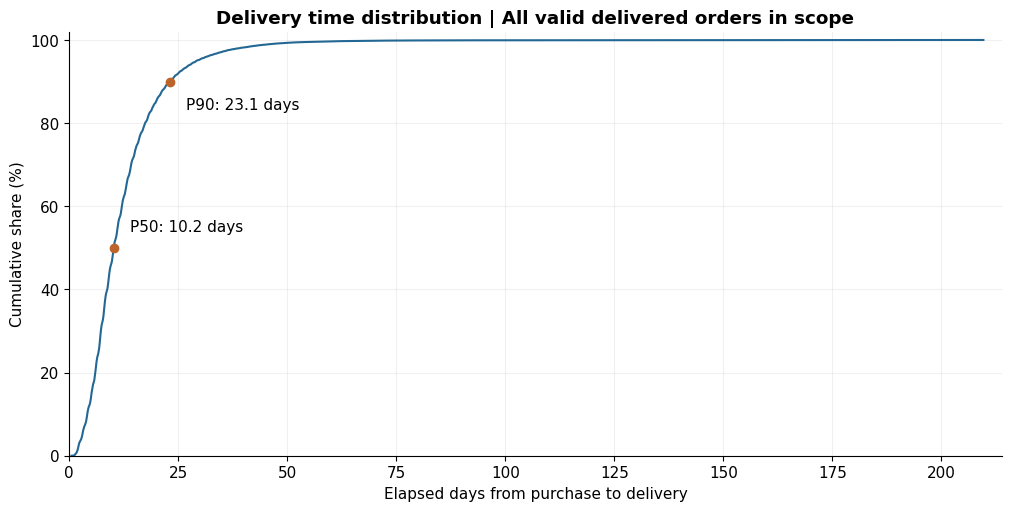

In [8]:
display(figures["05_delivery_duration"])

## SQL и сверка результатов

SQLite создаётся из той же витрины. Все запросы выполняются автоматически; ключевые суммы и количества сверяются с pandas.

In [9]:
export_results(ROOT, mart, summary, tables, figures, prepared)
with sqlite3.connect(ROOT / "data/processed/olist.sqlite") as connection:
    for path in sorted((ROOT / "sql").glob("*.sql")):
        print(path.name)
        display(pd.read_sql_query(path.read_text(), connection).head(10))
print((ROOT / "reports/validation.json").read_text())

01_order_amounts.sql
02_state_delivery.sql
03_monthly_trend.sql
04_reviews.sql
05_state_ranking.sql
{
  "status": "passed",
  "checks": [
    "Unique keys and referential integrity",
    "One row per order after all joins",
    "Exact integer-cent reconciliation of merchandise and payments",
    "All SQL queries executed on SQLite",
    "SQL/Python count and amount reconciliations"
  ],
  "environment": {
    "python": "3.12.14",
    "pandas": "2.2.3",
    "numpy": "2.3.5",
    "sqlite": "3.53.1"
  }
}


,order_id,order_status,item_count,merchandise_cents,freight_cents,payment_count,payment_cents,difference_cents
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,1.0,2999.0,872.0,3.0,3871.0,0.0
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,1.0,11870.0,2276.0,1.0,14146.0,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,1.0,15990.0,1922.0,1.0,17912.0,0.0
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,1.0,4500.0,2720.0,1.0,7220.0,0.0
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,1.0,1990.0,872.0,1.0,2862.0,0.0
5,a4591c265e18cb1dcee52889e2d8acc3,delivered,1.0,14790.0,2736.0,1.0,17526.0,0.0
6,136cce7faa42fdb2cefd53fdc79a6098,invoiced,1.0,4990.0,1605.0,1.0,6595.0,0.0
7,6514b8ad8028c9f2cc2374ded245783f,delivered,1.0,5999.0,1517.0,1.0,7516.0,0.0
8,76c6e866289321a7c93b82b54852dc33,delivered,1.0,1990.0,1605.0,1.0,3595.0,0.0
9,e69bfb5eb88e0ed6a785585b27e16dbf,delivered,1.0,14999.0,1977.0,2.0,16976.0,0.0


,customer_state,eligible_orders,late_orders,late_pct,mean_delivery_days
0,SP,40399,1817,4.50,8.74
1,RJ,12310,1495,12.14,15.30
2,MG,11319,519,4.59,11.98
3,BA,3253,396,12.17,19.33
4,RS,5327,325,6.10,15.29
5,SC,3537,291,8.23,14.95
6,ES,1992,214,10.74,15.78
7,PR,4903,199,4.06,11.97
8,CE,1273,176,13.83,21.24
9,PE,1587,153,9.64,18.45


,purchase_month,orders,delivered_orders,merchandise_brl,previous_month_orders,orders_mom_pct
0,2017-01,800,750,111798.36,NaN,NaN
1,2017-02,1780,1653,234223.40,800.0,122.50
2,2017-03,2682,2546,359198.85,1780.0,50.67
3,2017-04,2404,2303,340669.68,2682.0,-10.37
4,2017-05,3700,3546,489338.25,2404.0,53.91
5,2017-06,3245,3135,421923.37,3700.0,-12.30
6,2017-07,4026,3872,481604.52,3245.0,24.07
7,2017-08,4331,4193,554699.70,4026.0,7.58
8,2017-09,4285,4150,607399.67,4331.0,-1.06
9,2017-10,4631,4478,648247.65,4285.0,8.07


,late,reviewed_orders,mean_review,low_reviews,low_review_pct
0,0,89182,4.291,8247,9.25
1,1,6378,2.271,3981,62.42


,customer_state,eligible_orders,late_orders,late_rate,volume_rank,rate_rank
0,SP,40399,1817,0.044976,1,16
1,RJ,12310,1495,0.121446,2,4
2,MG,11319,519,0.045852,3,15
3,BA,3253,396,0.121734,4,3
4,RS,5327,325,0.061010,5,12
5,SC,3537,291,0.082273,6,10
6,ES,1992,214,0.107430,7,6
7,PR,4903,199,0.040587,8,17
8,CE,1273,176,0.138256,9,2
9,PE,1587,153,0.096408,10,9


## Выводы

1. Доля задержек — 6,79%; начать операционную диагностику целесообразно с RJ и SP.
2. Момент опроса покупателей существенно влияет на интерпретацию отзывов.
3. Медиана доставки — 10,21 дня, P90 — 23,06 дня; среднее не отражает длинный хвост.
4. Результаты относятся к исторической выборке доставленных заказов. Для оценки улучшений нужны свежие данные и план измерения эффекта.

Подробный отчёт: `reports/analysis_report.md`. Участие ChatGPT: `docs/AI_USAGE.md`.